# Exploratory Data Analysis: Pima Indians Diabetes

Before training anything, we look at the data to answer three questions:
1. **Class balance**: how many patients have diabetes vs. not?
2. **Distributions**: what do the values look like, and is anything suspicious?
3. **Correlations**: which measurements move together with the outcome?

Each row is one female patient (Pima heritage, age 21+). `Outcome` = 1 means she was diagnosed with diabetes within 5 years.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
df.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


## 1. Class balance

**Class imbalance** means one outcome is much more common than the other. If 65% of patients are healthy, a model that *always* says "healthy" scores 65% accuracy while being useless, so accuracy alone can't be trusted here.

Outcome
0    500
1    268
Name: count, dtype: int64

34.9% of patients have diabetes


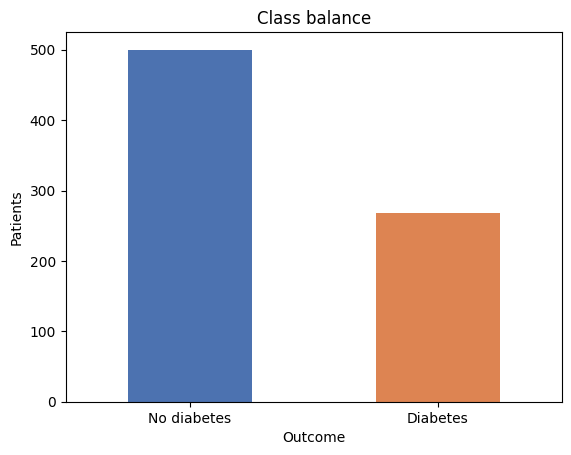

In [3]:
counts = df["Outcome"].value_counts().sort_index()
print(counts)
print(f"\n{counts[1] / len(df):.1%} of patients have diabetes")

counts.rename({0: "No diabetes", 1: "Diabetes"}).plot.bar(color=["#4C72B0", "#DD8452"], rot=0)
plt.title("Class balance")
plt.ylabel("Patients")
plt.show()

## 2. Hidden missing values: the zeros

Look at the `min` row of `describe()` above: **Glucose, BloodPressure, SkinThickness, Insulin and BMI all have a minimum of 0**.
A living person can't have a blood pressure or BMI of 0, so these zeros are really **missing values** that were recorded as 0.
(Zero *is* valid for `Pregnancies`, so we leave that column alone.)

If we don't fix this, the model learns that "0 glucose" is a real reading, which distorts everything. We'll replace them in Milestone 3.

In [4]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zeros = (df[zero_cols] == 0).sum()
pd.DataFrame({"zero_count": zeros, "percent": (zeros / len(df) * 100).round(1)})

,zero_count,percent
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


Insulin is missing for about half the patients and SkinThickness for about 30%. That's a lot, and it's a limitation worth mentioning in the README.

## 3. Distributions

Histograms split by outcome show which features separate the two groups. Notice the spikes at 0 in the columns listed above.

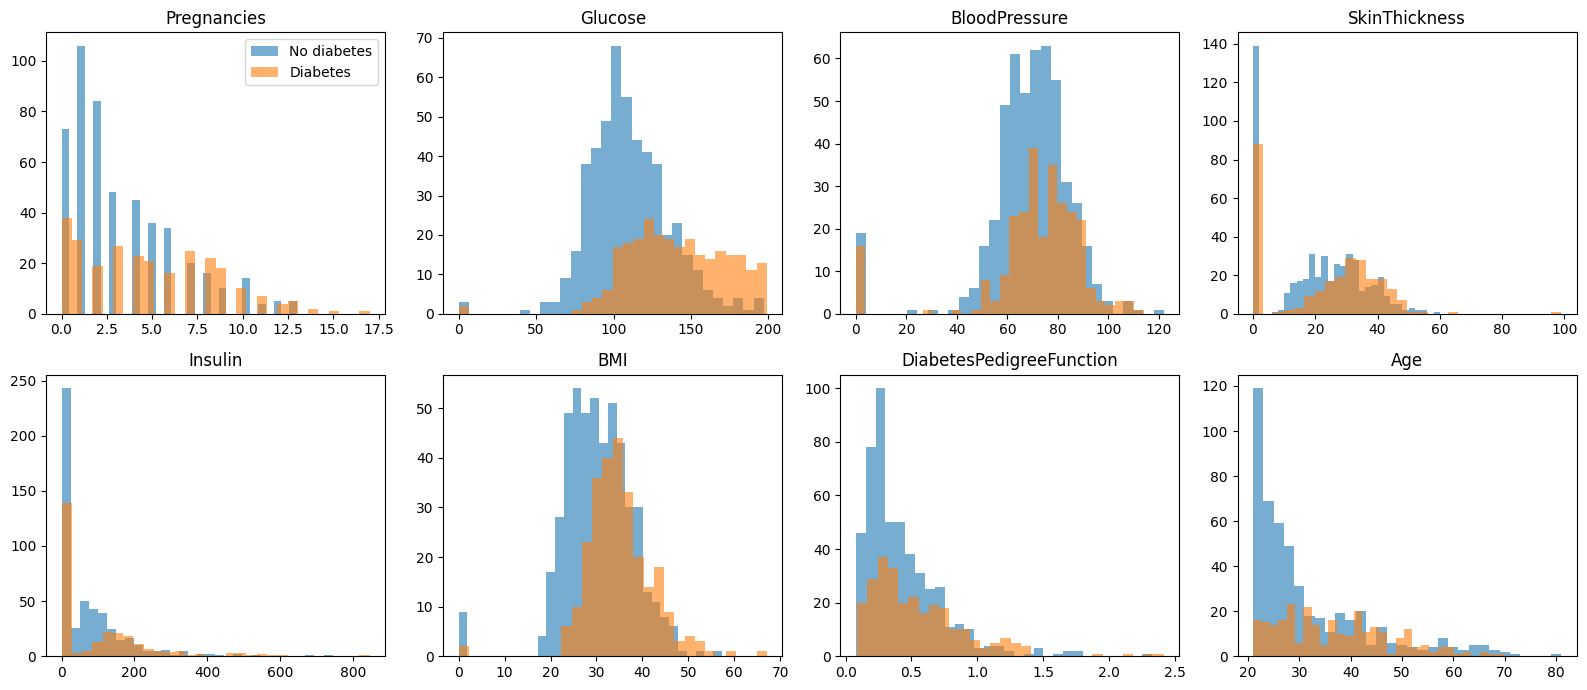

In [5]:
features = df.columns.drop("Outcome")
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, features):
    ax.hist(df.loc[df.Outcome == 0, col], bins=30, alpha=0.6, label="No diabetes")
    ax.hist(df.loc[df.Outcome == 1, col], bins=30, alpha=0.6, label="Diabetes")
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 4. Correlations

**Correlation** (from -1 to +1) measures how strongly two columns rise and fall together. It only catches straight-line relationships, but it's a quick first look at which features matter.

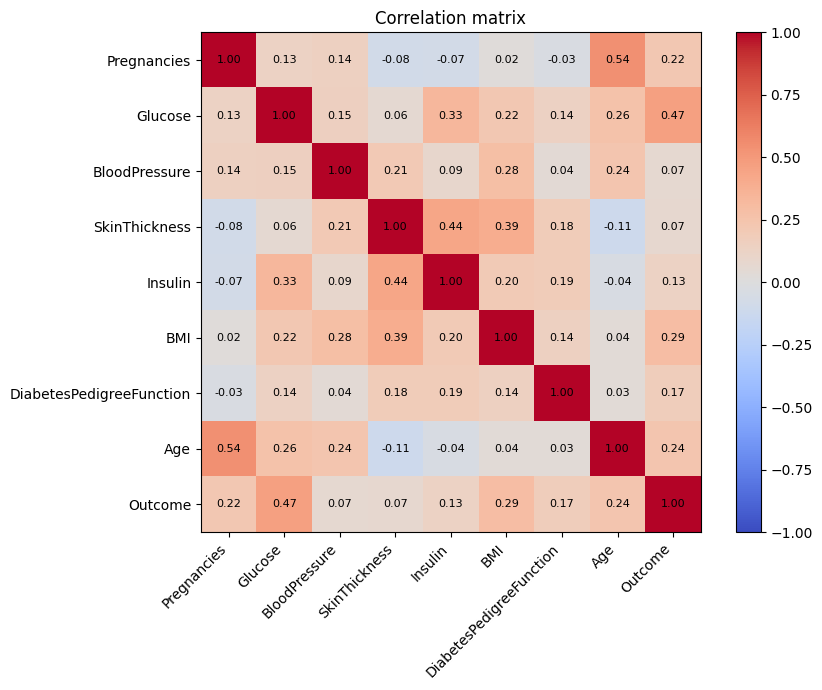

In [6]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [7]:
corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3)

Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64

## Takeaways

- **Imbalanced classes (~35% diabetic)**: we'll use a *stratified* split and judge models on recall/F1/ROC-AUC, not just accuracy.
- **Zeros are missing values** in 5 columns: we'll replace them with the column median (Milestone 3).
- **Glucose is by far the strongest single signal**, followed by BMI, Age and Pregnancies. We should expect the model and SHAP to agree.
- Age and Pregnancies are correlated with each other (older women tend to have had more pregnancies), which is useful to remember when reading explanations.